In [1]:
import pandas as pd

df = pd.read_csv("student_regression_5000.csv")
df.head()

,student_id,study_hours_per_day,attendance_percent,sleep_hours_per_night,exam_score,passed
0,S0001,3.84,41.5,5.38,47.6,0
1,S0002,4.06,93.5,4.43,78.5,1
2,S0003,2.53,41.8,5.09,35.2,0
3,S0004,1.19,79.0,6.72,47.1,0
4,S0005,1.32,75.4,8.05,63.7,1


In [2]:
df.shape

(5000, 6)

# Student Performance Prediction

This project uses 5,000 synthetic student records to build simple linear,
multiple linear, and logistic regression models.

The data is artificially generated for learning and does not represent
real students.

In [3]:
import pandas as pd

# Load the dataset from the same folder as this notebook.
df = pd.read_csv("student_regression_5000.csv")

# Check the number of rows and columns.
print("Dataset shape:", df.shape)

# Display the first five records.
df.head()

Dataset shape: (5000, 6)


,student_id,study_hours_per_day,attendance_percent,sleep_hours_per_night,exam_score,passed
0,S0001,3.84,41.5,5.38,47.6,0
1,S0002,4.06,93.5,4.43,78.5,1
2,S0003,2.53,41.8,5.09,35.2,0
3,S0004,1.19,79.0,6.72,47.1,0
4,S0005,1.32,75.4,8.05,63.7,1


In [4]:
# Check whether any values are missing in each column.
print("Missing values:")
print(df.isnull().sum())

# Check how Python interprets each column.
print("\nData types:")
print(df.dtypes)

# Count students in each outcome category.
print("\nPass/fail counts:")
print(df["passed"].value_counts())

Missing values:
student_id               0
study_hours_per_day      0
attendance_percent       0
sleep_hours_per_night    0
exam_score               0
passed                   0
dtype: int64

Data types:
student_id                   str
study_hours_per_day      float64
attendance_percent       float64
sleep_hours_per_night    float64
exam_score               float64
passed                     int64
dtype: object

Pass/fail counts:
passed
1    3006
0    1994
Name: count, dtype: int64


## Simple Linear Regression

Predict exam score using daily study hours.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# X contains the input used to make predictions.
X = df[["study_hours_per_day"]]

# y contains the answer we want the model to learn to predict.
y = df["exam_score"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4000
Testing records: 1000


In [9]:
# Create the model.
simple_model = LinearRegression()

# Learn the slope and intercept from the training records only.
simple_model.fit(X_train, y_train)

print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])

Intercept: 35.45928928494195
Slope: 6.177204348214238


Matplotlib is building the font cache; this may take a moment.


MAE: 9.11
RMSE: 11.34
R²: 0.492


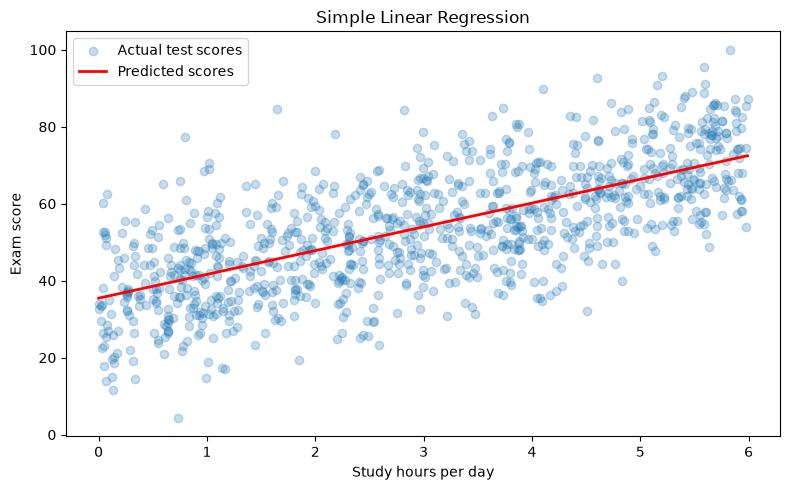

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict exam scores for the unseen test records.
simple_predictions = simple_model.predict(X_test)

simple_mae = mean_absolute_error(y_test, simple_predictions)
simple_rmse = np.sqrt(mean_squared_error(y_test, simple_predictions))
simple_r2 = r2_score(y_test, simple_predictions)

print(f"MAE: {simple_mae:.2f}")
print(f"RMSE: {simple_rmse:.2f}")
print(f"R²: {simple_r2:.3f}")

# Sort study hours so the fitted line is drawn in the correct order.
order = np.argsort(X_test["study_hours_per_day"].to_numpy())

plt.figure(figsize=(8, 5))
plt.scatter(
    X_test["study_hours_per_day"], y_test,
    alpha=0.25, label="Actual test scores"
)
plt.plot(
    X_test["study_hours_per_day"].to_numpy()[order],
    simple_predictions[order],
    color="red", linewidth=2, label="Predicted scores"
)
plt.xlabel("Study hours per day")
plt.ylabel("Exam score")
plt.title("Simple Linear Regression")
plt.legend()
plt.tight_layout()
plt.show()

# Multiple Linear Regression

In [12]:
features = [
    "study_hours_per_day",
    "attendance_percent",
    "sleep_hours_per_night"
]

# Use the same students as the simple model for a fair comparison.
X_multiple_train = df.loc[X_train.index, features]
X_multiple_test = df.loc[X_test.index, features]

multiple_model = LinearRegression()
multiple_model.fit(X_multiple_train, y_train)

multiple_predictions = multiple_model.predict(X_multiple_test)

multiple_mae = mean_absolute_error(y_test, multiple_predictions)
multiple_rmse = np.sqrt(mean_squared_error(y_test, multiple_predictions))
multiple_r2 = r2_score(y_test, multiple_predictions)

print(f"Intercept: {multiple_model.intercept_:.2f}")

for feature, coefficient in zip(features, multiple_model.coef_):
    print(f"{feature}: {coefficient:.2f}")

print(f"\nMAE: {multiple_mae:.2f}")
print(f"RMSE: {multiple_rmse:.2f}")
print(f"R²: {multiple_r2:.3f}")

Intercept: -5.06
study_hours_per_day: 6.09
attendance_percent: 0.40
sleep_hours_per_night: 1.98

MAE: 6.63
RMSE: 8.28
R²: 0.729


,Model,MAE,RMSE,R_squared
0,Simple Linear Regression,9.106,11.342,0.492
1,Multiple Linear Regression,6.626,8.281,0.729


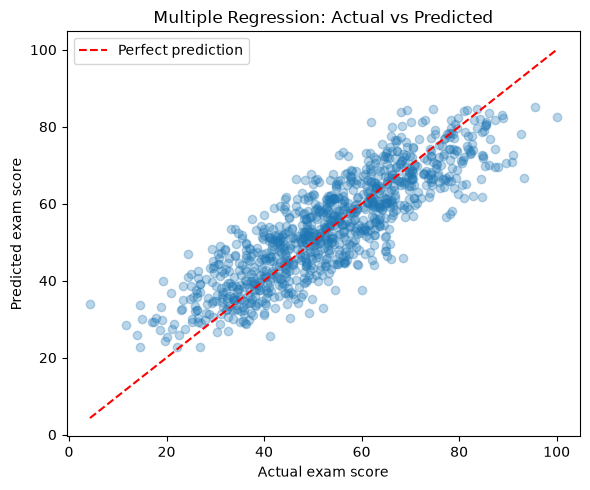

In [13]:
comparison = pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "MAE": [simple_mae, multiple_mae],
    "RMSE": [simple_rmse, multiple_rmse],
    "R_squared": [simple_r2, multiple_r2]
})

display(comparison.round(3))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, multiple_predictions, alpha=0.3)

# Points closer to this line represent more accurate predictions.
limits = [
    min(y_test.min(), multiple_predictions.min()),
    max(y_test.max(), multiple_predictions.max())
]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual exam score")
plt.ylabel("Predicted exam score")
plt.title("Multiple Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

# Logistic Regression

Majority-class baseline accuracy: 60.10%
Logistic regression accuracy: 82.80%
ROC-AUC: 0.915

Classification report:
              precision    recall  f1-score   support

        Fail       0.79      0.78      0.78       399
        Pass       0.85      0.86      0.86       601

    accuracy                           0.83      1000
   macro avg       0.82      0.82      0.82      1000
weighted avg       0.83      0.83      0.83      1000



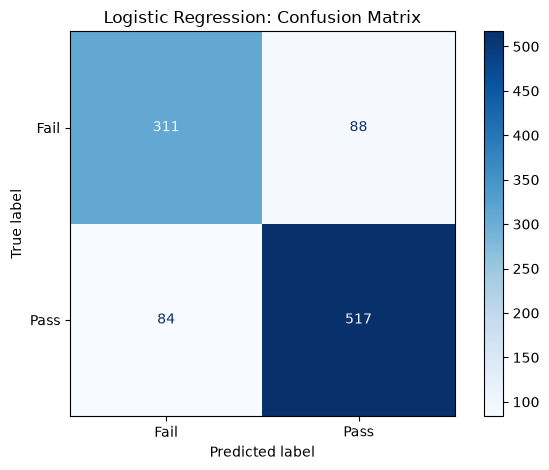

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

X_logistic = df[features]
y_logistic = df["passed"]

# Preserve approximately the same pass/fail proportions in both sets.
X_log_train, X_log_test, y_log_train, y_log_test = train_test_split(
    X_logistic,
    y_logistic,
    test_size=0.2,
    random_state=42,
    stratify=y_logistic
)

# Learn scaling from training data only, then train the classifier.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

logistic_model.fit(X_log_train, y_log_train)

logistic_predictions = logistic_model.predict(X_log_test)
pass_probabilities = logistic_model.predict_proba(X_log_test)[:, 1]

logistic_accuracy = accuracy_score(y_log_test, logistic_predictions)
logistic_auc = roc_auc_score(y_log_test, pass_probabilities)

# Baseline: always predict the most common training class.
majority_class = y_log_train.mode()[0]
baseline_accuracy = (y_log_test == majority_class).mean()

print(f"Majority-class baseline accuracy: {baseline_accuracy:.2%}")
print(f"Logistic regression accuracy: {logistic_accuracy:.2%}")
print(f"ROC-AUC: {logistic_auc:.3f}")

print("\nClassification report:")
print(classification_report(
    y_log_test,
    logistic_predictions,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_log_test,
    logistic_predictions,
    labels=[0, 1],
    display_labels=["Fail", "Pass"],
    cmap="Blues"
)
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
new_student = pd.DataFrame({
    "study_hours_per_day": [3.0],
    "attendance_percent": [85.0],
    "sleep_hours_per_night": [7.0]
})

simple_score = simple_model.predict(
    new_student[["study_hours_per_day"]]
)[0]

multiple_score = multiple_model.predict(new_student)[0]
predicted_class = logistic_model.predict(new_student)[0]
pass_probability = logistic_model.predict_proba(new_student)[0, 1]

print(f"Simple regression predicted score: {simple_score:.2f}")
print(f"Multiple regression predicted score: {multiple_score:.2f}")
print("Logistic regression outcome:",
      "Pass" if predicted_class == 1 else "Fail")
print(f"Estimated probability of passing: {pass_probability:.2%}")

Simple regression predicted score: 53.99
Multiple regression predicted score: 61.01
Logistic regression outcome: Pass
Estimated probability of passing: 92.02%


In [16]:
print(
    f"Simple linear regression achieved MAE={simple_mae:.2f}, "
    f"RMSE={simple_rmse:.2f}, and R²={simple_r2:.3f}."
)

print(
    f"Multiple linear regression achieved MAE={multiple_mae:.2f}, "
    f"RMSE={multiple_rmse:.2f}, and R²={multiple_r2:.3f}."
)

print(
    f"Logistic regression achieved accuracy={logistic_accuracy:.2%} "
    f"and ROC-AUC={logistic_auc:.3f}, compared with a majority-class "
    f"baseline accuracy of {baseline_accuracy:.2%}."
)

print(
    "\nThese results describe artificially generated student records. "
    "They do not establish causal relationships or demonstrate "
    "performance on real students."
)

Simple linear regression achieved MAE=9.11, RMSE=11.34, and R²=0.492.
Multiple linear regression achieved MAE=6.63, RMSE=8.28, and R²=0.729.
Logistic regression achieved accuracy=82.80% and ROC-AUC=0.915, compared with a majority-class baseline accuracy of 60.10%.

These results describe artificially generated student records. They do not establish causal relationships or demonstrate performance on real students.
